# Ordering the cost gates

**Question:** Can changing the order of commuting RZZ gates reduce compiled resources?

I compare the original edge order, its reverse, and a magnitude-first order. Every circuit uses the same edges and angles; gates only move within a cost layer and never across a mixer. The graph and objective stay fixed.

## 1. Load the shared problem

The [setup notebook](hardware_setup.ipynb) builds the circuit and the score.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Build the three circuits

- **Original:** visit SNP pairs in their usual order: (1, 2), (1, 3), and so on.
- **Reverse:** visit those pairs in the opposite order.
- **Magnitude:** visit the pairs with the largest absolute coupling first, regardless of sign.

Only pairs with a nonzero coupling get an RZZ gate. For this small instance, I check that all three orders have the same ideal measurement distribution.

In [2]:
orders = ['original', 'reverse', 'magnitude']
circuits = {name: make_circuit(gate_order=name) for name in orders}
if ideal is not None:
    for circuit in circuits.values():
        assert np.allclose(logical_probabilities(circuit), ideal)
    print('Ideal distributions agree for all gate orders.')

Ideal distributions agree for all gate orders.


## 3. Compile with the same layout and seeds

The only intended difference is gate order. I report the distribution instead of selecting one lucky compilation.

In [3]:
physical = list(range(n))
compiled = {}
rows = []
for name, circuit in circuits.items():
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend, optimization_level=2, initial_layout=physical,
            routing_method='sabre', seed_transpiler=seed,
        )
        compiled[name, seed] = manager.run(circuit)
        rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
resource_table = pd.DataFrame(rows)
display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
        .agg(['median', 'min', 'max']))

2q gates         2q depth          depth        
            median min max   median min max median min max
method                                                    
original      28.0  26  28     23.0  21  23   57.0  57  57
reverse       35.0  31  35     32.0  29  32   58.0  52  60
magnitude     31.0  29  31     20.0  18  20   44.0  42  44

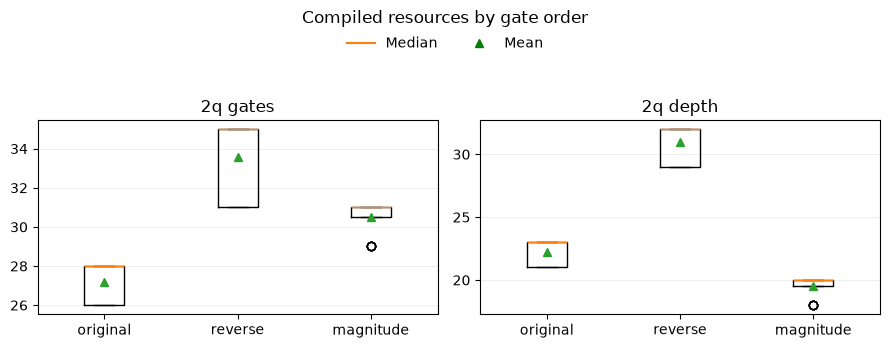

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric in zip(axes, ['2q gates', '2q depth']):
    data = [resource_table.loc[resource_table.method == name, metric] for name in orders]
    ax.boxplot(data, tick_labels=orders, showmeans=True)
    ax.set_title(metric)
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Compiled resources by gate order')
boxplot_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 4. Check noisy samples

I compare three compiled seeds and three noisy repeats per seed. The interaction graph stays fixed here because removing edges changes the objective; graph pruning needs its own controlled comparison.

In [5]:
run_noise = True
if run_noise:
    if backend.num_qubits > 16:
        raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    samples = []
    for name in orders:
        for seed in noise_seeds:
            for repeat in range(noise_repeats):
                counts = simulator.run(
                    compiled[name, seed], shots=shots,
                    seed_simulator=9000 + seed * 100 + repeat,
                ).result().get_counts()
                samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
    noisy_results = pd.DataFrame(samples)
    display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
            .agg(['mean', 'std']))

mean cost           optimum frequency          
               mean       std              mean       std
method                                                   
original   9.541992  0.211669          0.279514  0.011511
reverse    9.454156  0.271313          0.275716  0.018539
magnitude  9.452528  0.197627          0.276204  0.009534

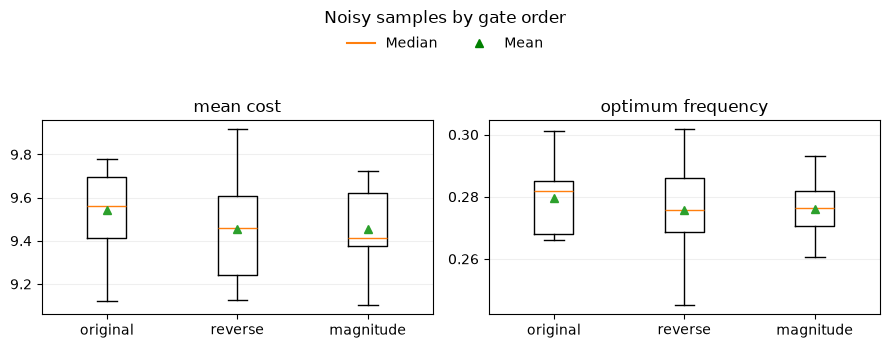

In [6]:
if run_noise:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        values = [noisy_results.loc[noisy_results.method == name, metric] for name in orders]
        ax.boxplot(values, tick_labels=orders, showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy samples by gate order')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

## What did I find?

All three gate orders had the same ideal output distribution. In the saved run, the original order had the lowest median two-qubit gate count (28); ordering by magnitude used more gates (31) but had lower two-qubit depth (20 instead of 23). Reverse order used the most gates.

The noisy mean costs and optimum frequencies were close compared with their variation, so fewer gates did not give a clear improvement in this small test. This result applies to the saved input and backend.